# Coupon Acceptance Patterns: Association Rule Mining for Targeted Coupon Delivery

Under what situational conditions are drivers most likely to accept coupon offers, and how can these patterns be used to improve coupon targeting?

MSc Business Analytics coursework, University of Greenwich (2025–26).  
Module: Business Data Mining and Visual Analytics (COMP1943).

## 1. Data Loading and Inspection

In [1]:
#Importing Libraries
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
from pathlib import Path

# Folder for the key charts used in the README
FIG_DIR = Path('../figures')
FIG_DIR.mkdir(exist_ok=True)

In [2]:
# loading the dataset
df = pd.read_csv('../data/Coupon_Recommendation.csv')
df.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Male,21,Single,...,less1,4~8,4~8,less1,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,0,1,0


In [3]:
# Checking data types and missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12079 entries, 0 to 12078
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   destination           12079 non-null  str  
 1   passanger             12079 non-null  str  
 2   weather               12079 non-null  str  
 3   temperature           12079 non-null  int64
 4   time                  12079 non-null  str  
 5   coupon                12079 non-null  str  
 6   expiration            12079 non-null  str  
 7   gender                12079 non-null  str  
 8   age                   12079 non-null  str  
 9   maritalStatus         12079 non-null  str  
 10  has_children          12079 non-null  int64
 11  education             12079 non-null  str  
 12  occupation            12079 non-null  str  
 13  income                12079 non-null  str  
 14  Bar                   12079 non-null  str  
 15  CoffeeHouse           12079 non-null  str  
 16  CarryAway      

In [4]:
# Checking for missing values
df.isna().sum().sort_values(ascending=False)

destination             0
passanger               0
weather                 0
temperature             0
time                    0
coupon                  0
expiration              0
gender                  0
age                     0
maritalStatus           0
has_children            0
education               0
occupation              0
income                  0
Bar                     0
CoffeeHouse             0
CarryAway               0
RestaurantLessThan20    0
Restaurant20To50        0
toCoupon_GEQ5min        0
toCoupon_GEQ15min       0
toCoupon_GEQ25min       0
direction_same          0
direction_opp           0
Y                       0
dtype: int64

In [5]:
# Checking for duplicates
print(f"Duplicate rows: {df.duplicated().sum()}")

Duplicate rows: 72


In [6]:
# Reviewing column cardinality
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns\n")
for col in df.columns:
    print(f"  {col}: {df[col].nunique()} unique values")

Shape: 12079 rows x 25 columns

  destination: 3 unique values
  passanger: 4 unique values
  weather: 3 unique values
  temperature: 3 unique values
  time: 5 unique values
  coupon: 5 unique values
  expiration: 2 unique values
  gender: 2 unique values
  age: 8 unique values
  maritalStatus: 5 unique values
  has_children: 2 unique values
  education: 6 unique values
  occupation: 25 unique values
  income: 9 unique values
  Bar: 5 unique values
  CoffeeHouse: 5 unique values
  CarryAway: 5 unique values
  RestaurantLessThan20: 5 unique values
  Restaurant20To50: 5 unique values
  toCoupon_GEQ5min: 1 unique values
  toCoupon_GEQ15min: 2 unique values
  toCoupon_GEQ25min: 2 unique values
  direction_same: 2 unique values
  direction_opp: 2 unique values
  Y: 2 unique values


## 2. Modelling Goal and Baseline

In [7]:
# Y=1 means the driver accepted the coupon, Y=0 means rejected
# Finding the baseline acceptance rate to judge whether rules are meaningful
base_rate = df["Y"].mean()
print(f"Baseline acceptance rate P(Y=1): {base_rate:.3f}")

print("\nClass distribution:")
print(df["Y"].value_counts(normalize=True))

Baseline acceptance rate P(Y=1): 0.569

Class distribution:
Y
1    0.569335
0    0.430665
Name: proportion, dtype: float64


## 3. Exploratory Data Analysis

                       acceptance_rate
coupon                                
Carry out & Take away         0.737719
Restaurant(<20)               0.709009
Coffee House                  0.496331
Restaurant(20-50)             0.446013
Bar                           0.411918


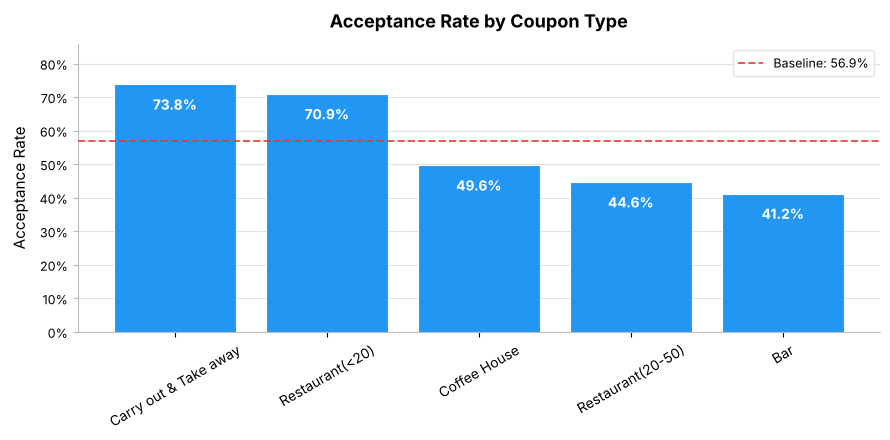

In [8]:
# Acceptance rate by coupon type
coupon_accept = df.groupby("coupon")["Y"].mean().sort_values(ascending=False)
print(coupon_accept.to_frame("acceptance_rate"))

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(coupon_accept.index.astype(str), coupon_accept.values,
              color='#2196F3', edgecolor='white', linewidth=0.8, zorder=3)

# Baseline line
ax.axhline(y=base_rate, color='#E53935', linestyle='--', linewidth=1.4,
           alpha=0.85, label=f'Baseline: {base_rate:.1%}', zorder=4)

# Value labels — inside bar (white) if bar is tall enough, above otherwise
for bar, val in zip(bars, coupon_accept.values):
    label_y  = bar.get_height() - 0.035
    color    = 'white'
    va       = 'top'
    if bar.get_height() < 0.12:          # very short bar: put label above
        label_y, color, va = bar.get_height() + 0.008, '#1565C0', 'bottom'
    ax.text(bar.get_x() + bar.get_width() / 2, label_y,
            f'{val:.1%}', ha='center', va=va,
            fontsize=10, fontweight='bold', color=color, zorder=5)

# Gridlines and spines
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#E0E0E0', linewidth=0.8, linestyle='-')
ax.set_facecolor('white')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
ax.spines['left'].set_color('#BDBDBD')
ax.spines['bottom'].set_color('#BDBDBD')

# Labels and formatting
ax.set_ylabel('Acceptance Rate', fontsize=11, labelpad=8)
ax.set_ylim(0, max(coupon_accept.values) + 0.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_title('Acceptance Rate by Coupon Type', fontsize=13, fontweight='bold', pad=12)
ax.tick_params(axis='x', rotation=30, labelsize=10)
ax.tick_params(axis='y', labelsize=9, color='#BDBDBD')
ax.legend(frameon=True, framealpha=0.9, edgecolor='#E0E0E0', fontsize=9)
plt.tight_layout()
fig.savefig(FIG_DIR / 'acceptance_by_coupon_type.png', dpi=150, bbox_inches='tight')
plt.show()


      acceptance_rate
time                 
7AM          0.503968
10AM         0.607970
2PM          0.660752
6PM          0.582846
10PM         0.515502


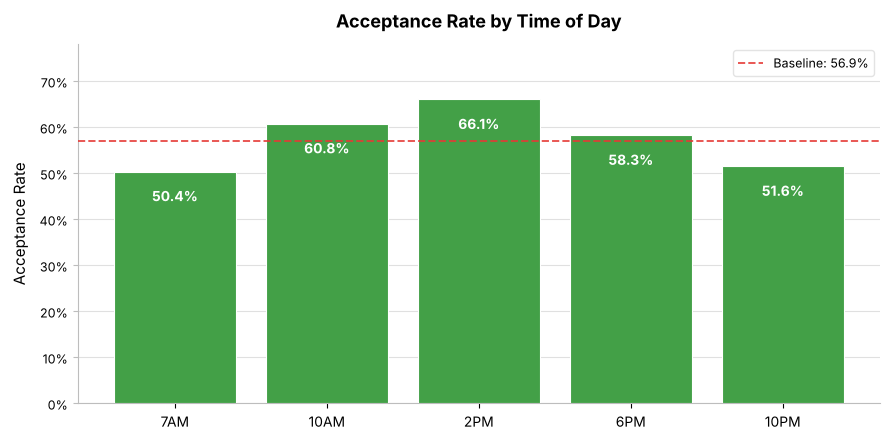

In [9]:
# Acceptance rate by time of day
time_order = ['7AM', '10AM', '2PM', '6PM', '10PM']
time_accept = df.groupby("time")["Y"].mean().reindex(time_order)
print(time_accept.to_frame("acceptance_rate"))

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(time_accept.index.astype(str), time_accept.values,
              color='#43A047', edgecolor='white', linewidth=0.8, zorder=3)

ax.axhline(y=base_rate, color='#E53935', linestyle='--', linewidth=1.4,
           alpha=0.85, label=f'Baseline: {base_rate:.1%}', zorder=4)

for bar, val in zip(bars, time_accept.values):
    label_y = bar.get_height() - 0.035
    color   = 'white'
    va      = 'top'
    if bar.get_height() < 0.12:
        label_y, color, va = bar.get_height() + 0.008, '#1B5E20', 'bottom'
    ax.text(bar.get_x() + bar.get_width() / 2, label_y,
            f'{val:.1%}', ha='center', va=va,
            fontsize=10, fontweight='bold', color=color, zorder=5)

ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#E0E0E0', linewidth=0.8)
ax.set_facecolor('white')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
ax.spines['left'].set_color('#BDBDBD')
ax.spines['bottom'].set_color('#BDBDBD')

ax.set_ylabel('Acceptance Rate', fontsize=11, labelpad=8)
ax.set_ylim(0, max(time_accept.values) + 0.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_title('Acceptance Rate by Time of Day', fontsize=13, fontweight='bold', pad=12)
ax.tick_params(axis='x', labelsize=10)
ax.tick_params(axis='y', labelsize=9, color='#BDBDBD')
ax.legend(frameon=True, framealpha=0.9, edgecolor='#E0E0E0', fontsize=9)
plt.tight_layout()
plt.show()


         acceptance_rate
weather                 
Sunny           0.595042
Snowy           0.476334
Rainy           0.462075


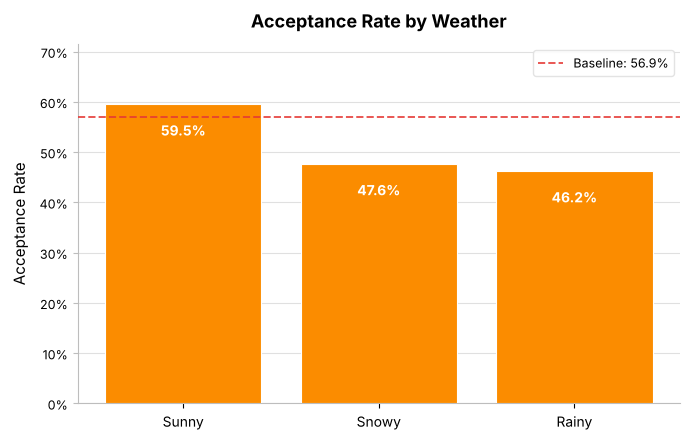

In [10]:
# Acceptance rate by weather
weather_accept = df.groupby("weather")["Y"].mean().sort_values(ascending=False)
print(weather_accept.to_frame("acceptance_rate"))

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(weather_accept.index.astype(str), weather_accept.values,
              color='#FB8C00', edgecolor='white', linewidth=0.8, zorder=3)

ax.axhline(y=base_rate, color='#E53935', linestyle='--', linewidth=1.4,
           alpha=0.85, label=f'Baseline: {base_rate:.1%}', zorder=4)

for bar, val in zip(bars, weather_accept.values):
    label_y = bar.get_height() - 0.035
    color   = 'white'
    va      = 'top'
    if bar.get_height() < 0.12:
        label_y, color, va = bar.get_height() + 0.008, '#E65100', 'bottom'
    ax.text(bar.get_x() + bar.get_width() / 2, label_y,
            f'{val:.1%}', ha='center', va=va,
            fontsize=10, fontweight='bold', color=color, zorder=5)

ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#E0E0E0', linewidth=0.8)
ax.set_facecolor('white')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
ax.spines['left'].set_color('#BDBDBD')
ax.spines['bottom'].set_color('#BDBDBD')

ax.set_ylabel('Acceptance Rate', fontsize=11, labelpad=8)
ax.set_ylim(0, max(weather_accept.values) + 0.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_title('Acceptance Rate by Weather', fontsize=13, fontweight='bold', pad=12)
ax.tick_params(axis='x', labelsize=10)
ax.tick_params(axis='y', labelsize=9, color='#BDBDBD')
ax.legend(frameon=True, framealpha=0.9, edgecolor='#E0E0E0', fontsize=9)
plt.tight_layout()
plt.show()


                 acceptance_rate
destination                     
No Urgent Place         0.634003
Home                    0.508266
Work                    0.503968


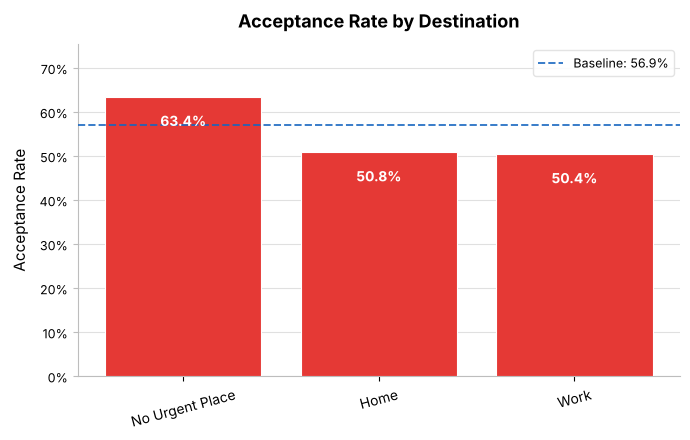

In [11]:
# Acceptance rate by destination
dest_accept = df.groupby("destination")["Y"].mean().sort_values(ascending=False)
print(dest_accept.to_frame("acceptance_rate"))

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(dest_accept.index.astype(str), dest_accept.values,
              color='#E53935', edgecolor='white', linewidth=0.8, zorder=3)

ax.axhline(y=base_rate, color='#1565C0', linestyle='--', linewidth=1.4,
           alpha=0.85, label=f'Baseline: {base_rate:.1%}', zorder=4)

for bar, val in zip(bars, dest_accept.values):
    label_y = bar.get_height() - 0.035
    color   = 'white'
    va      = 'top'
    if bar.get_height() < 0.12:
        label_y, color, va = bar.get_height() + 0.008, '#B71C1C', 'bottom'
    ax.text(bar.get_x() + bar.get_width() / 2, label_y,
            f'{val:.1%}', ha='center', va=va,
            fontsize=10, fontweight='bold', color=color, zorder=5)

ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#E0E0E0', linewidth=0.8)
ax.set_facecolor('white')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
ax.spines['left'].set_color('#BDBDBD')
ax.spines['bottom'].set_color('#BDBDBD')

ax.set_ylabel('Acceptance Rate', fontsize=11, labelpad=8)
ax.set_ylim(0, max(dest_accept.values) + 0.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_title('Acceptance Rate by Destination', fontsize=13, fontweight='bold', pad=12)
ax.tick_params(axis='x', rotation=15, labelsize=10)
ax.tick_params(axis='y', labelsize=9, color='#BDBDBD')
ax.legend(frameon=True, framealpha=0.9, edgecolor='#E0E0E0', fontsize=9)
plt.tight_layout()
plt.show()


           acceptance_rate
passanger                 
Friend(s)         0.676302
Partner           0.594727
Alone             0.527048
Kid(s)            0.496802


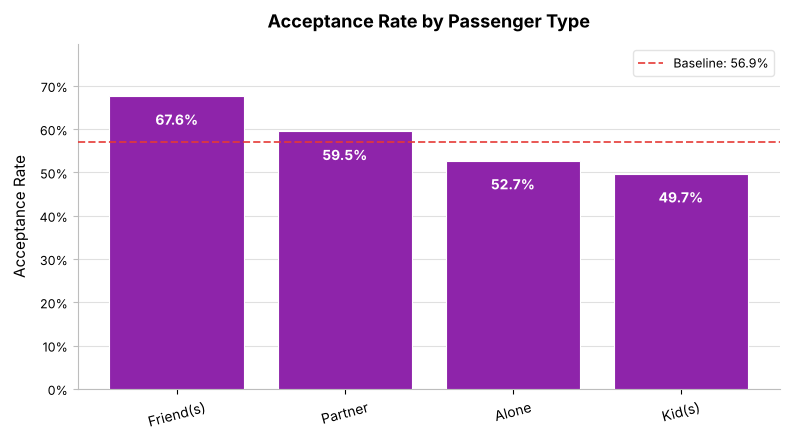

In [12]:
# Acceptance rate by passenger type
pass_accept = df.groupby("passanger")["Y"].mean().sort_values(ascending=False)
print(pass_accept.to_frame("acceptance_rate"))

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(pass_accept.index.astype(str), pass_accept.values,
              color='#8E24AA', edgecolor='white', linewidth=0.8, zorder=3)

ax.axhline(y=base_rate, color='#E53935', linestyle='--', linewidth=1.4,
           alpha=0.85, label=f'Baseline: {base_rate:.1%}', zorder=4)

for bar, val in zip(bars, pass_accept.values):
    label_y = bar.get_height() - 0.035
    color   = 'white'
    va      = 'top'
    if bar.get_height() < 0.12:
        label_y, color, va = bar.get_height() + 0.008, '#4A148C', 'bottom'
    ax.text(bar.get_x() + bar.get_width() / 2, label_y,
            f'{val:.1%}', ha='center', va=va,
            fontsize=10, fontweight='bold', color=color, zorder=5)

ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#E0E0E0', linewidth=0.8)
ax.set_facecolor('white')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
ax.spines['left'].set_color('#BDBDBD')
ax.spines['bottom'].set_color('#BDBDBD')

ax.set_ylabel('Acceptance Rate', fontsize=11, labelpad=8)
ax.set_ylim(0, max(pass_accept.values) + 0.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_title('Acceptance Rate by Passenger Type', fontsize=13, fontweight='bold', pad=12)
ax.tick_params(axis='x', rotation=15, labelsize=10)
ax.tick_params(axis='y', labelsize=9, color='#BDBDBD')
ax.legend(frameon=True, framealpha=0.9, edgecolor='#E0E0E0', fontsize=9)
plt.tight_layout()
plt.show()


## 4. Data Preprocessing

In [13]:
# toCoupon_GEQ5min has only 1 unique value so it adds no information
print(f"toCoupon_GEQ5min unique values: {df['toCoupon_GEQ5min'].nunique()}")

df_clean = df.drop(columns=['toCoupon_GEQ5min'])

# Removing duplicate rows to avoid inflating support counts
n_before = df_clean.shape[0]
df_clean = df_clean.drop_duplicates()
n_after = df_clean.shape[0]
print(f"\nDuplicates removed: {n_before - n_after}")
print(f"Rows remaining: {n_after}")

toCoupon_GEQ5min unique values: 1

Duplicates removed: 72
Rows remaining: 12007


## 5. Transaction Construction

In [14]:
# Selecting columns that cover context, offer, demographics, behaviour, and outcome
selected_cols = [
    "destination", "passanger", "weather", "temperature", "time",
    "coupon", "expiration",
    "gender", "age", "maritalStatus", "has_children", "education", "income",
    "Bar", "CoffeeHouse", "CarryAway", "RestaurantLessThan20", "Restaurant20To50",
    "toCoupon_GEQ15min", "toCoupon_GEQ25min", "direction_same", "direction_opp",
    "Y"
]

# Each row becomes a list of "column=value" strings
transactions = [
    [f"{col}={row[col]}" for col in selected_cols]
    for _, row in df_clean[selected_cols].astype(str).iterrows()
]

print(f"Number of transactions: {len(transactions)}")
print(f"\nExample transaction (first row):")
print(transactions[0])

Number of transactions: 12007

Example transaction (first row):
['destination=No Urgent Place', 'passanger=Alone', 'weather=Sunny', 'temperature=55', 'time=2PM', 'coupon=Restaurant(<20)', 'expiration=1d', 'gender=Male', 'age=21', 'maritalStatus=Single', 'has_children=0', 'education=Bachelors degree', 'income=$62500 - $74999', 'Bar=never', 'CoffeeHouse=less1', 'CarryAway=4~8', 'RestaurantLessThan20=4~8', 'Restaurant20To50=less1', 'toCoupon_GEQ15min=0', 'toCoupon_GEQ25min=0', 'direction_same=0', 'direction_opp=1', 'Y=1']


In [15]:
# Validating transaction lengths
lens = [len(t) for t in transactions]
print(f"Avg items per transaction: {np.mean(lens):.1f} | Min: {np.min(lens)} | Max: {np.max(lens)}")

Avg items per transaction: 23.0 | Min: 23 | Max: 23


## 6. One-Hot Encoding

In [16]:
# TransactionEncoder converts the list of transactions into a boolean matrix
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
df_hot = pd.DataFrame(te_array, columns=te.columns_)

print("One-hot shape:", df_hot.shape)
df_hot.head()

One-hot shape: (12007, 92)


,Bar=1~3,Bar=4~8,Bar=gt8,Bar=less1,Bar=never,CarryAway=1~3,CarryAway=4~8,CarryAway=gt8,CarryAway=less1,CarryAway=never,...,time=2PM,time=6PM,time=7AM,toCoupon_GEQ15min=0,toCoupon_GEQ15min=1,toCoupon_GEQ25min=0,toCoupon_GEQ25min=1,weather=Rainy,weather=Snowy,weather=Sunny
0,False,False,False,False,True,False,True,False,False,False,...,True,False,False,True,False,True,False,False,False,True
1,False,False,False,False,True,False,True,False,False,False,...,False,False,False,True,False,True,False,False,False,True
2,False,False,False,False,True,False,True,False,False,False,...,False,False,False,True,False,True,False,False,False,True
3,False,False,False,False,True,False,True,False,False,False,...,False,False,False,False,True,True,False,False,False,True
4,False,False,False,False,True,False,True,False,False,False,...,True,False,False,True,False,True,False,False,False,True


In [17]:
# Checking sparsity
true_rate = df_hot.values.mean()
print(f"Overall density (proportion of True): {true_rate:.4f}")

Overall density (proportion of True): 0.2500


## 7. Frequent Itemset Mining

In [18]:
# Mining frequent itemsets with Apriori
# min_support=0.05 keeps itemsets in at least 5% of transactions
# max_len=3 keeps rules short and interpretable
min_support = 0.05
max_len = 3

freq_itemsets = apriori(
    df_hot,
    min_support=min_support,
    use_colnames=True,
    max_len=max_len
)

print(f"Frequent itemsets: {freq_itemsets.shape[0]}")
freq_itemsets.sort_values("support", ascending=False).head(10)

Frequent itemsets: 10205


,support,itemsets
79,0.883734,frozenset({toCoupon_GEQ25min=0})
83,0.794953,frozenset({weather=Sunny})
39,0.784043,frozenset({direction_opp=1})
40,0.784043,frozenset({direction_same=0})
1177,0.784043,"frozenset({direction_opp=1, direction_same=0})"
1668,0.733156,"frozenset({toCoupon_GEQ25min=0, weather=Sunny})"
1257,0.667777,"frozenset({toCoupon_GEQ25min=0, direction_same..."
1215,0.667777,"frozenset({toCoupon_GEQ25min=0, direction_opp=1})"
8303,0.667777,"frozenset({toCoupon_GEQ25min=0, direction_opp=..."
8307,0.616640,"frozenset({direction_opp=1, direction_same=0, ..."


## 8. Association Rule Generation

In [19]:
# Generating rules with min confidence of 0.60
min_confidence = 0.60

rules = association_rules(
    freq_itemsets,
    metric="confidence",
    min_threshold=min_confidence,
    num_itemsets=len(freq_itemsets)
)

print(f"All rules: {rules.shape[0]}")
rules.head()

All rules: 8590


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({Bar=1~3}),frozenset({Y=1}),0.196968,0.568418,0.122928,0.624101,1.097961,1.0,0.010968,1.148133,0.111105,0.191340,0.129021,0.420183
1,frozenset({Bar=1~3}),frozenset({direction_opp=1}),0.196968,0.784043,0.154327,0.783510,0.999320,1.0,-0.000105,0.997537,-0.000847,0.186681,-0.002469,0.490172
2,frozenset({Bar=1~3}),frozenset({direction_same=0}),0.196968,0.784043,0.154327,0.783510,0.999320,1.0,-0.000105,0.997537,-0.000847,0.186681,-0.002469,0.490172
3,frozenset({Bar=1~3}),frozenset({has_children=0}),0.196968,0.591155,0.133256,0.676533,1.144425,1.0,0.016817,1.263945,0.157153,0.203485,0.208826,0.450974
4,frozenset({Bar=1~3}),frozenset({toCoupon_GEQ25min=0}),0.196968,0.883734,0.175398,0.890486,1.007640,1.0,0.001330,1.061652,0.009442,0.193744,0.058072,0.544480


In [20]:
# Keeping only rules where the consequent is Y=1
rules_y1 = rules[
    rules["consequents"].apply(lambda s: len(s) == 1 and "Y=1" in s)
].copy()

print(f"Rules with consequent Y=1: {rules_y1.shape[0]}")

# Adding a comparison against the baseline
rules_y1["confidence_minus_baseline"] = rules_y1["confidence"] - base_rate

# Ranking by lift, then confidence
top_rules = rules_y1.sort_values(
    ["lift", "confidence", "support"], ascending=False
).head()

top_rules[["antecedents", "consequents", "support", "confidence", "lift",
           "confidence_minus_baseline"]]

Rules with consequent Y=1: 332


,antecedents,consequents,support,confidence,lift,confidence_minus_baseline
3861,"frozenset({expiration=1d, coupon=Restaurant(<2...",frozenset({Y=1}),0.089698,0.835531,1.469923,0.266196
3870,"frozenset({passanger=Friend(s), coupon=Restaur...",frozenset({Y=1}),0.052803,0.803549,1.413657,0.234214
3853,"frozenset({destination=No Urgent Place, coupon...",frozenset({Y=1}),0.107604,0.794588,1.397893,0.225253
1837,"frozenset({CoffeeHouse=1~3, passanger=Friend(s)})",frozenset({Y=1}),0.055551,0.787485,1.385397,0.218150
3829,"frozenset({coupon=Carry out & Take away, expir...",frozenset({Y=1}),0.088032,0.784707,1.380509,0.215372


## 9. Actionable Rule Filtering

In [21]:
# Keeping rules where the antecedent includes a coupon type
if rules_y1.shape[0] == 0:
    print("No rules found. Try lowering thresholds.")
else:
    rules_offer = rules_y1[
        rules_y1["antecedents"].apply(
            lambda s: any(str(x).startswith("coupon=") for x in s)
        )
    ].copy()
    print(f"Rules with coupon in antecedent AND Y=1: {rules_offer.shape[0]}")

    # Limiting antecedent length for interpretability
    rules_offer["antecedent_len"] = rules_offer["antecedents"].apply(len)
    rules_offer_small = rules_offer[rules_offer["antecedent_len"] <= 3].copy()
    print(f"Of which antecedent_len <= 3: {rules_offer_small.shape[0]}")

    display(
        rules_offer_small
        .sort_values(["lift", "confidence", "support"], ascending=False)
        .head(15)[["antecedents", "consequents", "support", "confidence",
                    "lift", "confidence_minus_baseline", "antecedent_len"]]
    )

Rules with coupon in antecedent AND Y=1: 47
Of which antecedent_len <= 3: 47


,antecedents,consequents,support,confidence,lift,confidence_minus_baseline,antecedent_len
3861,"frozenset({expiration=1d, coupon=Restaurant(<2...",frozenset({Y=1}),0.089698,0.835531,1.469923,0.266196,2
3870,"frozenset({passanger=Friend(s), coupon=Restaur...",frozenset({Y=1}),0.052803,0.803549,1.413657,0.234214,2
3853,"frozenset({destination=No Urgent Place, coupon...",frozenset({Y=1}),0.107604,0.794588,1.397893,0.225253,2
3829,"frozenset({coupon=Carry out & Take away, expir...",frozenset({Y=1}),0.088032,0.784707,1.380509,0.215372,2
3878,"frozenset({coupon=Restaurant(<20), weather=Sun...",frozenset({Y=1}),0.136420,0.767932,1.350999,0.198597,2
3845,"frozenset({coupon=Carry out & Take away, weath...",frozenset({Y=1}),0.104439,0.762774,1.341923,0.193439,2
3823,"frozenset({destination=No Urgent Place, coupon...",frozenset({Y=1}),0.058716,0.760518,1.337954,0.191183,2
3831,"frozenset({gender=Male, coupon=Carry out & Tak...",frozenset({Y=1}),0.068627,0.759447,1.336070,0.190112,2
3872,"frozenset({temperature=80, coupon=Restaurant(<...",frozenset({Y=1}),0.094611,0.759358,1.335914,0.190023,2
3873,"frozenset({toCoupon_GEQ15min=0, coupon=Restaur...",frozenset({Y=1}),0.092529,0.757328,1.332342,0.187993,2


## 10. Rule Quality Visualisation

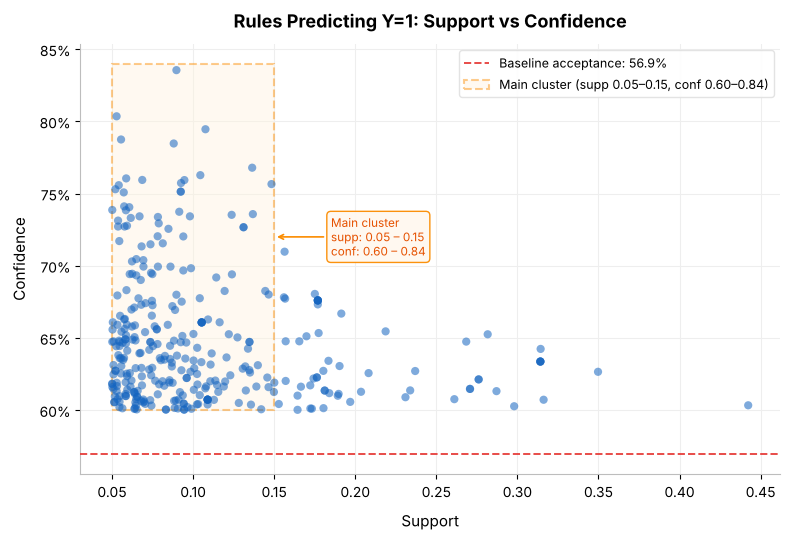

In [22]:
# Support vs Confidence scatter for Y=1 rules
if rules_y1.shape[0] > 0:
    from matplotlib.patches import Rectangle

    fig, ax = plt.subplots(figsize=(8, 5.5))

    # Scatter points
    ax.scatter(rules_y1["support"], rules_y1["confidence"],
               s=35, alpha=0.55, color='#1565C0', edgecolors='none', zorder=3)

    # Baseline
    ax.axhline(y=base_rate, linestyle='--', color='#E53935', linewidth=1.4,
               alpha=0.9, label=f'Baseline acceptance: {base_rate:.1%}', zorder=4)

    # Main cluster rectangle
    rect = Rectangle((0.05, 0.60), 0.10, 0.24,
                     linewidth=1.5, edgecolor='#FB8C00', facecolor='#FFF3E0',
                     alpha=0.45, linestyle='--', zorder=2,
                     label='Main cluster (supp 0.05\u20130.15, conf 0.60\u20130.84)')
    ax.add_patch(rect)

    # Annotation box with arrow pointing into the cluster
    annot_text = 'Main cluster\nsupp: 0.05 \u2013 0.15\nconf: 0.60 \u2013 0.84'
    ax.annotate(
        annot_text,
        xy=(0.15, 0.72), xytext=(0.185, 0.72),
        fontsize=8.5, color='#E65100', va='center', ha='left',
        arrowprops=dict(arrowstyle='->', color='#FB8C00', lw=1.2),
        bbox=dict(boxstyle='round,pad=0.35', fc='#FFF8F0',
                  ec='#FB8C00', lw=1.0, alpha=0.95)
    )

    # Grid and spines
    ax.set_axisbelow(True)
    ax.grid(True, color='#EEEEEE', linewidth=0.8)
    ax.set_facecolor('white')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.spines['left'].set_color('#BDBDBD')
    ax.spines['bottom'].set_color('#BDBDBD')

    ax.set_xlabel('Support', fontsize=11, labelpad=8)
    ax.set_ylabel('Confidence', fontsize=11, labelpad=8)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.2f}'))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax.set_title('Rules Predicting Y=1: Support vs Confidence',
                 fontsize=13, fontweight='bold', pad=12)
    ax.legend(frameon=True, framealpha=0.9, edgecolor='#E0E0E0',
              fontsize=9, loc='upper right')
    plt.tight_layout()
    fig.savefig(FIG_DIR / 'support_vs_confidence.png', dpi=150, bbox_inches='tight')
    plt.show()


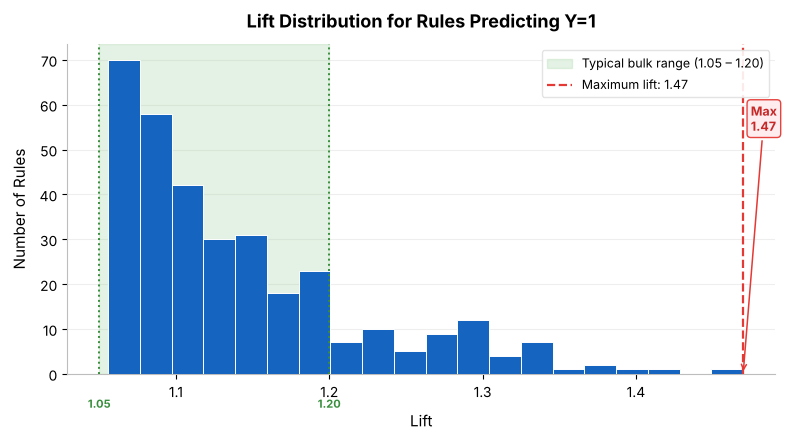

In [23]:
# Lift distribution for Y=1 rules
if rules_y1.shape[0] > 0:
    max_lift = rules_y1['lift'].max()

    fig, ax = plt.subplots(figsize=(8, 4.5))

    # Histogram
    n, bins, patches = ax.hist(rules_y1['lift'], bins=20,
                               color='#1565C0', edgecolor='white',
                               linewidth=0.7, zorder=3)

    # Shade typical bulk region AFTER histogram so ylim is known
    ax.axvspan(1.05, 1.20, color='#A5D6A7', alpha=0.30,
               label='Typical bulk range (1.05 – 1.20)', zorder=2)
    ax.axvline(x=1.05, color='#388E3C', linestyle=':', linewidth=1.4, zorder=4)
    ax.axvline(x=1.20, color='#388E3C', linestyle=':', linewidth=1.4, zorder=4)

    # Max-lift marker
    ax.axvline(x=max_lift, color='#E53935', linestyle='--',
               linewidth=1.6, zorder=5, label=f'Maximum lift: {max_lift:.2f}')

    # Max-lift label — placed just above the x-axis using a fixed bbox
    y_top = ax.get_ylim()[1]
    ax.annotate(
        f'Max\n{max_lift:.2f}',
        xy=(max_lift, 0), xytext=(max_lift + 0.005, y_top * 0.82),
        fontsize=9, color='#C62828', fontweight='bold', ha='left', va='top',
        arrowprops=dict(arrowstyle='->', color='#E53935', lw=1.1),
        bbox=dict(boxstyle='round,pad=0.3', fc='#FFEBEE',
                  ec='#E53935', lw=1.0, alpha=0.95)
    )

    # Bulk-range x-tick labels
    ax.text(1.05, -y_top * 0.07, '1.05', ha='center', va='top',
            fontsize=8, color='#388E3C', fontweight='bold',
            transform=ax.transData, clip_on=False)
    ax.text(1.20, -y_top * 0.07, '1.20', ha='center', va='top',
            fontsize=8, color='#388E3C', fontweight='bold',
            transform=ax.transData, clip_on=False)

    # Grid and spines
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, color='#EEEEEE', linewidth=0.8)
    ax.set_facecolor('white')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.spines['left'].set_color('#BDBDBD')
    ax.spines['bottom'].set_color('#BDBDBD')

    ax.set_xlabel('Lift', fontsize=11, labelpad=8)
    ax.set_ylabel('Number of Rules', fontsize=11, labelpad=8)
    ax.set_title('Lift Distribution for Rules Predicting Y=1',
                 fontsize=13, fontweight='bold', pad=12)
    ax.legend(frameon=True, framealpha=0.9, edgecolor='#E0E0E0',
              fontsize=9, loc='upper right')
    plt.tight_layout()
    plt.show()


## 11. Threshold Sensitivity Analysis

In [24]:
# Testing multiple threshold combinations to justify chosen parameters
supports = [0.02, 0.03, 0.05, 0.08]
confidences = [0.55, 0.60, 0.65, 0.70]
results = []

for sup in supports:
    fi = apriori(df_hot, min_support=sup, use_colnames=True, max_len=3)
    for conf in confidences:
        r = association_rules(fi, metric="confidence", min_threshold=conf,
                              num_itemsets=len(fi))
        r_y1 = r[r["consequents"].apply(lambda s: "Y=1" in set(s))]
        n_rules = r_y1.shape[0]
        avg_lift = r_y1["lift"].mean() if n_rules > 0 else np.nan
        results.append({
            "min_support": sup, "min_confidence": conf,
            "n_rules_Y1": n_rules, "avg_lift_Y1": avg_lift
        })

grid = pd.DataFrame(results)
grid

,min_support,min_confidence,n_rules_Y1,avg_lift_Y1
0,0.02,0.55,1245,1.104263
1,0.02,0.60,703,1.158346
2,0.02,0.65,286,1.241037
3,0.02,0.70,111,1.301601
4,0.03,0.55,984,1.104445
5,0.03,0.60,540,1.158196
6,0.03,0.65,215,1.245193
7,0.03,0.70,84,1.304549
8,0.05,0.55,659,1.107835
9,0.05,0.60,352,1.159265


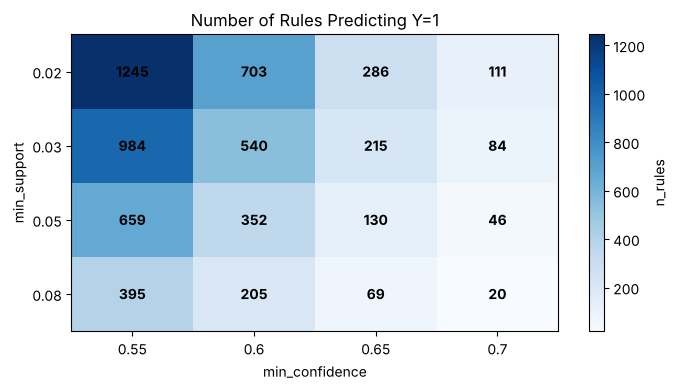

In [25]:
# Heatmap: Number of Y=1 rules by threshold combination
pivot_n = grid.pivot(index="min_support", columns="min_confidence", values="n_rules_Y1").sort_index()

plt.figure(figsize=(7, 4))
plt.imshow(pivot_n.values, aspect="auto", cmap="Blues")
plt.xticks(range(len(pivot_n.columns)), pivot_n.columns)
plt.yticks(range(len(pivot_n.index)), pivot_n.index)
plt.xlabel("min_confidence")
plt.ylabel("min_support")
plt.title("Number of Rules Predicting Y=1")
plt.colorbar(label="n_rules")
for i in range(len(pivot_n.index)):
    for j in range(len(pivot_n.columns)):
        plt.text(j, i, int(pivot_n.values[i, j]),
                 ha="center", va="center", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / 'threshold_sensitivity_n_rules.png', dpi=150, bbox_inches='tight')
plt.show()

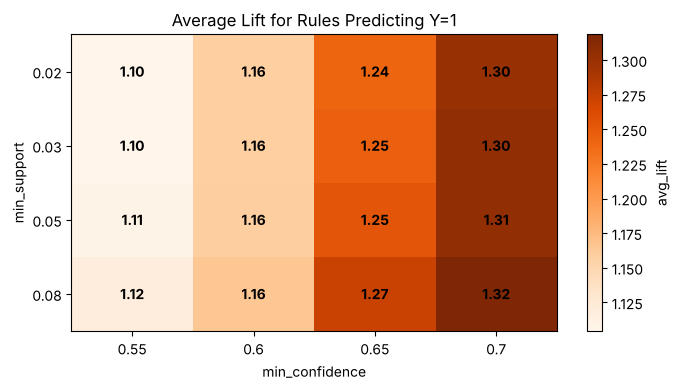

In [26]:
# Heatmap: Average lift by threshold combination
pivot_l = grid.pivot(index="min_support", columns="min_confidence", values="avg_lift_Y1").sort_index()

plt.figure(figsize=(7, 4))
plt.imshow(pivot_l.values, aspect="auto", cmap="Oranges")
plt.xticks(range(len(pivot_l.columns)), pivot_l.columns)
plt.yticks(range(len(pivot_l.index)), pivot_l.index)
plt.xlabel("min_confidence")
plt.ylabel("min_support")
plt.title("Average Lift for Rules Predicting Y=1")
plt.colorbar(label="avg_lift")
for i in range(len(pivot_l.index)):
    for j in range(len(pivot_l.columns)):
        val = pivot_l.values[i, j]
        if not np.isnan(val):
            plt.text(j, i, f"{val:.2f}",
                     ha="center", va="center", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

## 12. Top Rules Summary

In [27]:
# Printing the top rules for interpretation
if rules_y1.shape[0] > 0:
    summary = rules_y1.sort_values("lift", ascending=False).head(15)
    
    print("Top 15 Rules Predicting Coupon Acceptance (Y=1):")
    print("=" * 80)
    
    for i, (idx, row) in enumerate(summary.iterrows()):
        ant = ', '.join(sorted([str(x) for x in row['antecedents']]))
        print(f"\nRule {i+1}: IF [{ant}] -> THEN [Y=1]")
        print(f"  Support:    {row['support']:.3f}")
        print(f"  Confidence: {row['confidence']:.1%}")
        print(f"  Lift:       {row['lift']:.3f}")
        print(f"  vs Baseline: +{row['confidence_minus_baseline']:.1%}")
    
    print("\n" + "=" * 80)

Top 15 Rules Predicting Coupon Acceptance (Y=1):

Rule 1: IF [coupon=Restaurant(<20), expiration=1d] -> THEN [Y=1]
  Support:    0.090
  Confidence: 83.6%
  Lift:       1.470
  vs Baseline: +26.6%

Rule 2: IF [coupon=Restaurant(<20), passanger=Friend(s)] -> THEN [Y=1]
  Support:    0.053
  Confidence: 80.4%
  Lift:       1.414
  vs Baseline: +23.4%

Rule 3: IF [coupon=Restaurant(<20), destination=No Urgent Place] -> THEN [Y=1]
  Support:    0.108
  Confidence: 79.5%
  Lift:       1.398
  vs Baseline: +22.5%

Rule 4: IF [CoffeeHouse=1~3, passanger=Friend(s)] -> THEN [Y=1]
  Support:    0.056
  Confidence: 78.7%
  Lift:       1.385
  vs Baseline: +21.8%

Rule 5: IF [coupon=Carry out & Take away, expiration=1d] -> THEN [Y=1]
  Support:    0.088
  Confidence: 78.5%
  Lift:       1.381
  vs Baseline: +21.5%

Rule 6: IF [coupon=Restaurant(<20), weather=Sunny] -> THEN [Y=1]
  Support:    0.136
  Confidence: 76.8%
  Lift:       1.351
  vs Baseline: +19.9%

Rule 7: IF [coupon=Carry out & Take a

In [28]:
# Summary of overall results
print("MINING SUMMARY")
print("=" * 50)
print(f"Dataset rows (after cleaning): {df_clean.shape[0]}")
print(f"Transactions built:            {len(transactions)}")
print(f"One-hot columns:               {df_hot.shape[1]}")
print(f"Frequent itemsets:             {freq_itemsets.shape[0]}")
print(f"Total rules generated:         {rules.shape[0]}")
print(f"Rules predicting Y=1:          {rules_y1.shape[0]}")
print(f"Baseline acceptance rate:      {base_rate:.3f}")
print(f"\nChosen thresholds:")
print(f"  min_support:    {min_support}")
print(f"  min_confidence: {min_confidence}")
print(f"  max_len:        {max_len}")

MINING SUMMARY
Dataset rows (after cleaning): 12007
Transactions built:            12007
One-hot columns:               92
Frequent itemsets:             10205
Total rules generated:         8590
Rules predicting Y=1:          332
Baseline acceptance rate:      0.569

Chosen thresholds:
  min_support:    0.05
  min_confidence: 0.6
  max_len:        3
